# 5. Finite size: fluctuations and switching (Chapters 14–15)
$N$ two-state neurons: off→on at rate $f(wa+I)$, on→off at rate 1. Mean field: $\dot a = -a + (1-a)f(wa+I)$.

**Picture first:** a finite population is a cloud around the mean field state; with two wells, noise carries it over the ridge.

In [1]:
import numpy as np, matplotlib.pyplot as plt, pyxpp
plt.rcParams.update({"figure.figsize": (7, 4.2), "axes.spines.top": False, "axes.spines.right": False})
def load(name, **pars):
    m = pyxpp.load(text=open(f"ode/{name}.ode").read())
    if pars: m.set(**pars)
    return m

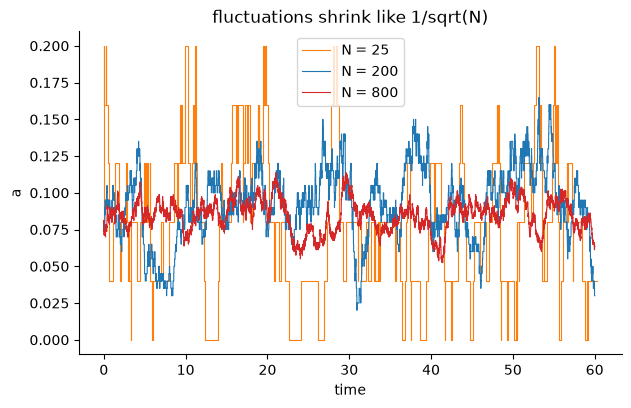

In [2]:
def gillespie(N, w, b, th, T, a0, seed=0):
    rng = np.random.default_rng(seed); n = int(a0*N); t = 0; ts, ns = [0], [n]
    f = lambda x: 1/(1+np.exp(-b*(x-th)))
    while t < T:
        up = (N-n)*f(w*n/N); dn = n; tot = up + dn
        t += rng.exponential(1/tot); n += 1 if rng.random()*tot < up else -1
        ts.append(t); ns.append(n)
    return np.array(ts), np.array(ns)/N
for N, c in [(25, 'C1'), (200, 'C0'), (800, 'C3')]:
    t, a = gillespie(N, 4, 2, 1.5, 60, 0.08, seed=N); plt.step(t, a, c, lw=0.8, label=f'N = {N}')
plt.xlabel('time'); plt.ylabel('a'); plt.legend(); plt.title('fluctuations shrink like 1/sqrt(N)');

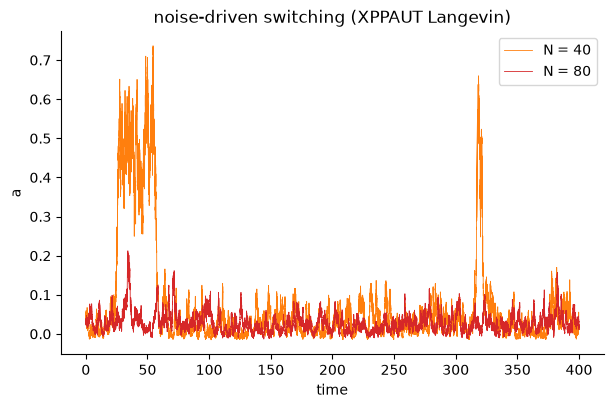

In [3]:
m = load('langevin_population')
for N, c in [(40, 'C1'), (80, 'C3')]:
    m.set(nn=N, a=0.025); tr = m.run(total=400)
    plt.plot(tr.t, tr['a'], c, lw=0.6, label=f'N = {N}')
plt.xlabel('time'); plt.ylabel('a'); plt.legend(); plt.title('noise-driven switching (XPPAUT Langevin)');

**Try:** double `nn` and measure how much longer the population waits before switching. Theory: about $e^{N\Delta\Phi}$ with $\Delta\Phi \approx 0.059$.